In [1]:
import site
site.addsitedir("/home/jovyan/vault/heidelberg_lulc_2025/pylibs/lib/python3.11/site-packages")
import os
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

PROJ = "/home/jovyan/vault/heidelberg_lulc_2025"
RUN = "segformer_train10_VV-VH-RATIO_s42"
MAPS = f"{PROJ}/outputs/maps/{RUN}/input10m"
OUT = f"{PROJ}/outputs/statistics"
os.makedirs(OUT, exist_ok=True)

CLASS_NAMES = ["Water", "Trees", "Grass", "Flooded vegetation", "Crops",
               "Shrub and scrub", "Built-up", "Bare ground", "Snow and ice"]
PALETTE = ["#419bdf", "#397d49", "#88b053", "#7a87c6", "#e49635",
           "#dfc35a", "#c4281b", "#a59b8f", "#b39fe1"]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

maps = {}
for m in range(1, 13):
    with rasterio.open(f"{MAPS}/LULC_2025_{m:02d}.tif") as src:
        maps[m] = src.read(1)
        px_area_km2 = abs(src.transform.a * src.transform.e) / 1e6

rows, area_rows = [], []
for m, a in maps.items():
    valid = a != 255
    cnt = np.bincount(a[valid], minlength=9)[:9]
    rows.append({"month": MONTHS[m - 1], **{c: 100 * cnt[i] / valid.sum() for i, c in enumerate(CLASS_NAMES)}})
    area_rows.append({"month": MONTHS[m - 1], **{c: cnt[i] * px_area_km2 for i, c in enumerate(CLASS_NAMES)}})

pct = pd.DataFrame(rows).set_index("month")                 # % of area per class
area = pd.DataFrame(area_rows).set_index("month")           # km² per class
mom = pct.diff()                                            # month-to-month change (pp)
total = (pct.loc["Dec"] - pct.loc["Jan"]).rename("Jan→Dec (pp)")

pct.round(3).to_csv(f"{OUT}/class_percent_per_month.csv")
area.round(3).to_csv(f"{OUT}/class_area_km2_per_month.csv")
mom.round(3).to_csv(f"{OUT}/month_to_month_change_pp.csv")
total.round(3).to_csv(f"{OUT}/total_change_jan_dec_pp.csv")

pd.set_option("display.width", 220)
print(f"Total mapped area: {sum(area.iloc[0]):.1f} km²  (pixel = {px_area_km2*1e6:.0f} m²)\n")
print("=== Class share per month (% of area) ===");        print(pct.round(2).to_string())
print("\n=== Month-to-month change (percentage points) ==="); print(mom.round(2).to_string())
print("\n=== Total change January → December (pp) ===");   print(total.round(2).to_string())
print(f"\nBuilt-up area: Jan {area.loc['Jan','Built-up']:.1f} km², Dec {area.loc['Dec','Built-up']:.1f} km²")

Total mapped area: 1595.2 km²  (pixel = 100 m²)

=== Class share per month (% of area) ===
       Water  Trees  Grass  Flooded vegetation  Crops  Shrub and scrub  Built-up  Bare ground  Snow and ice
month                                                                                                      
Jan     4.34  32.83  13.57                0.00  17.07             7.05     21.92         1.58          1.65
Feb     3.35  27.01  10.49                0.00  14.74             8.48     23.76         0.13         12.04
Mar     3.11  37.65   7.99                0.01  24.51             2.15     24.41         0.09          0.08
Apr     2.98  41.59   1.77                0.05  28.57             0.11     24.82         0.09          0.00
May     2.91  41.43   2.18                0.09  28.89             0.13     24.30         0.07          0.00
Jun     2.93  42.02   2.43                0.06  27.85             0.10     24.53         0.09          0.00
Jul     2.99  43.04   2.87                0.0

=== Model vs Dynamic World (same pixels) ===
       DW_coverage_%  agreement_%  Built-up model-DW (pp)  Trees model-DW (pp)  Crops model-DW (pp)  Grass model-DW (pp)
month                                                                                                                   
Jan            42.63        72.05                    1.38                -6.83                 1.62                 3.01
Feb           100.00        71.76                    1.15                -9.19                -0.94                 0.15
Mar            99.93        86.77                    0.83                -1.71                 0.76                 0.36
Apr           100.00        90.31                    0.79                -1.85                 1.67                -0.51
May           100.00        91.14                    0.28                -1.29                 1.21                -0.17
Jun           100.00        91.02                    0.75                -1.50                 1.18         

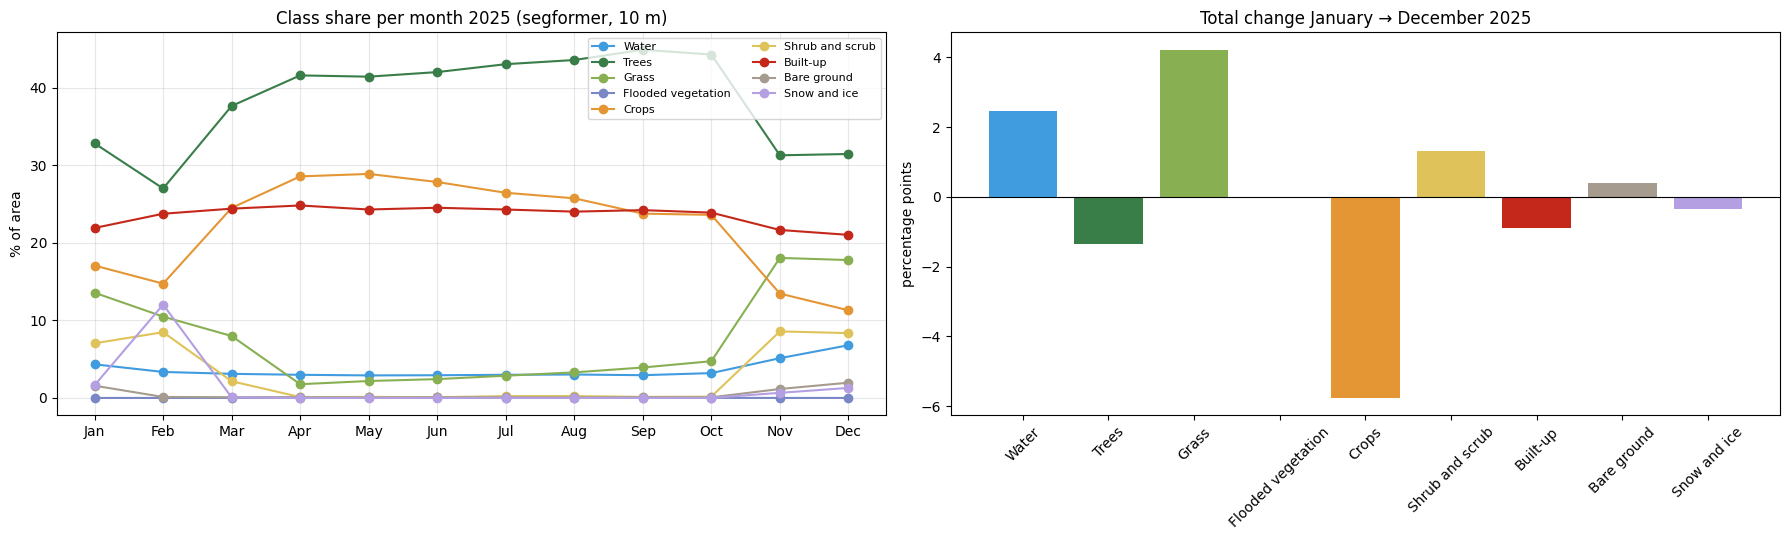

In [2]:
# --- model vs Dynamic World per month (only pixels where DW has a label) ---
cmp_rows = []
for m in range(1, 13):
    with rasterio.open(f"{PROJ}/outputs/aligned/10m/DW_2025_{m:02d}_10m_lulc.tif") as src:
        dw = src.read(1)
    both = (dw != 255) & (maps[m] != 255)
    cm = np.bincount(dw[both], minlength=9)[:9] / both.sum() * 100
    cp = np.bincount(maps[m][both], minlength=9)[:9] / both.sum() * 100
    cmp_rows.append({"month": MONTHS[m - 1], "DW_coverage_%": 100 * both.mean(),
                     "agreement_%": 100 * (dw[both] == maps[m][both]).mean(),
                     **{f"{c} model-DW (pp)": cp[i] - cm[i] for i, c in enumerate(CLASS_NAMES)}})
cmp = pd.DataFrame(cmp_rows).set_index("month")
cmp.round(2).to_csv(f"{OUT}/model_vs_dynamicworld_per_month.csv")
print("=== Model vs Dynamic World (same pixels) ===")
print(cmp[["DW_coverage_%", "agreement_%", "Built-up model-DW (pp)", "Trees model-DW (pp)",
           "Crops model-DW (pp)", "Grass model-DW (pp)"]].round(2).to_string())

# --- net vs gross change ---
gross_rows = []
for m in range(2, 13):
    v = (maps[m] != 255) & (maps[m - 1] != 255)
    gross_rows.append({"from→to": f"{MONTHS[m-2]}→{MONTHS[m-1]}",
                       "pixels_changed_%": 100 * (maps[m][v] != maps[m - 1][v]).mean(),
                       "sum_|net change| / 2 (pp)": mom.loc[MONTHS[m - 1]].abs().sum() / 2})
v = (maps[12] != 255) & (maps[1] != 255)
gross_rows.append({"from→to": "Jan→Dec", "pixels_changed_%": 100 * (maps[12][v] != maps[1][v]).mean(),
                   "sum_|net change| / 2 (pp)": total.abs().sum() / 2})
gross = pd.DataFrame(gross_rows).set_index("from→to")
gross.round(2).to_csv(f"{OUT}/gross_vs_net_change.csv")
print("\n=== Gross change (pixels that switched class) vs net change ===")
print(gross.round(2).to_string())

# --- figures ---
fig, axs = plt.subplots(1, 2, figsize=(18, 5.5))
for i, c in enumerate(CLASS_NAMES):
    axs[0].plot(MONTHS, pct[c], marker="o", color=PALETTE[i], label=c)
axs[0].set_ylabel("% of area"); axs[0].set_title(f"Class share per month 2025 ({RUN.split('_')[0]}, 10 m)")
axs[0].grid(alpha=0.3); axs[0].legend(fontsize=8, ncol=2)
axs[1].bar(CLASS_NAMES, total.values, color=PALETTE)
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set_ylabel("percentage points"); axs[1].set_title("Total change January → December 2025")
axs[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(f"{PROJ}/outputs/figures/monthly_class_share_and_total_change.png", dpi=150); plt.show()